# 04 — Chapman-Shaoxing Anomalies, Error Labels Catalog & `ChapmanShaoxingDataset` Filtering

Full-cohort catalog of all `10` `err_*` flags and `4` `severity_tier`s in `chapman_shaoxing/quality/error_labels.csv` across all `45,152` records, plus live `ChapmanShaoxingDataset` filtering.

,flag,count,pct_of_45152
8,err_dx_unmapped_code,13119,29.119
5,err_age_pediatric,1845,4.095
0,err_file_missing_or_corrupt,318,0.706
4,err_age_invalid_or_sentinel,247,0.548
3,err_age_missing,55,0.122
9,err_dx_sr_arrhythmia_conflict,26,0.058
6,err_sex_missing_or_unknown,22,0.049
2,err_hdr_nonstandard_fs_or_leads,1,0.002
1,err_hdr_nonstandard_duration,0,0.000
7,err_dx_empty,0,0.000


,severity_tier,recommended_action,count,pct
0,0_clean,keep,29708,65.94
1,1_minor_warning,keep_with_cleaning,1753,3.89
2,2_moderate_anomaly,review_or_downweight,13273,29.46
3,3_severe_error,exclude,319,0.71


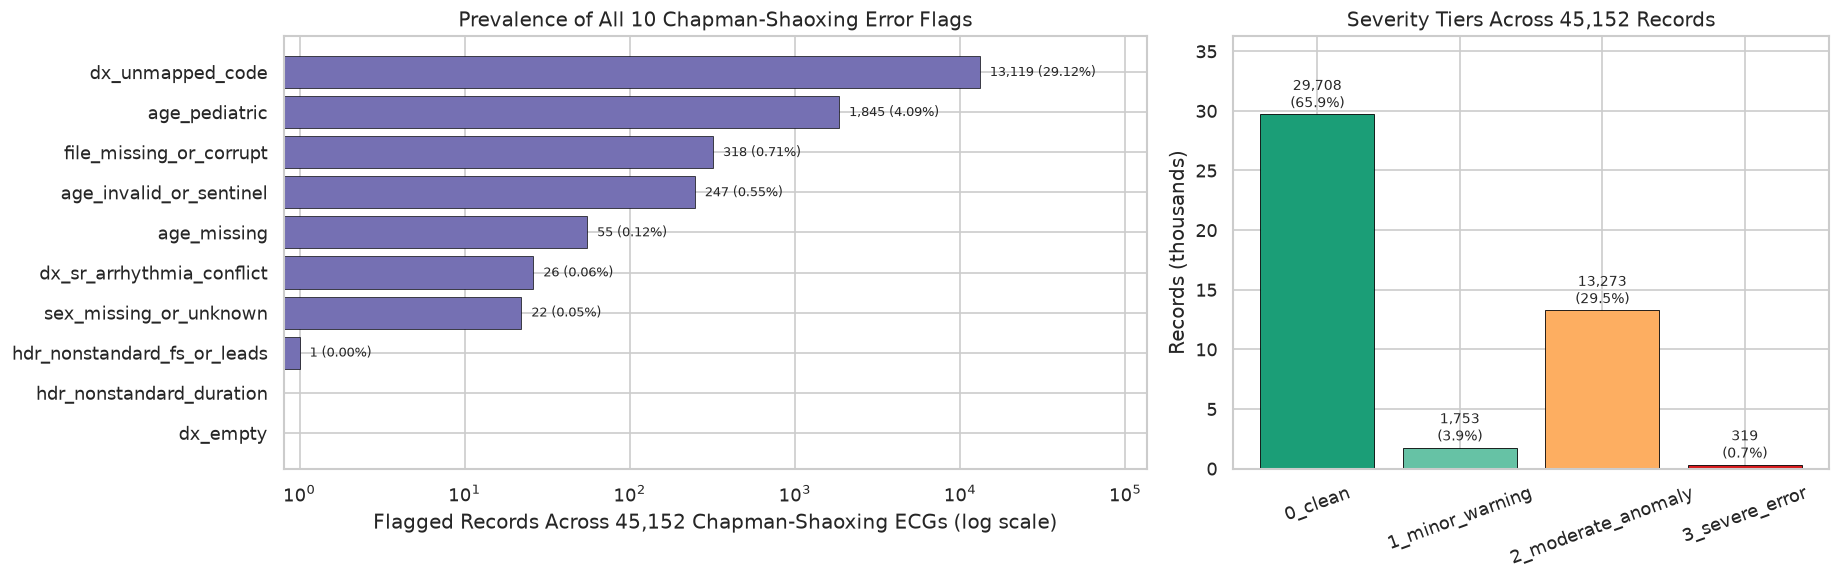

ChapmanShaoxingDataset -> total=45,052 | max_error_severity=2: 44,734 | gold (0): 29,708
Sample[0] signal: (12, 5000) | labels: ['AFIB', 'RBBB', 'TWC'] | severity: 0_clean


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "chapman_shaoxing" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate chapman_shaoxing/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from chapman_shaoxing import ChapmanShaoxingDataset

CHAPMAN_DIR = REPO_ROOT / "chapman_shaoxing"
DATA_DIR = CHAPMAN_DIR / "data"
QUALITY_DIR = CHAPMAN_DIR / "quality"
LEADS = ChapmanShaoxingDataset.LEADS

df = pd.read_csv(QUALITY_DIR / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")

flag_cols = [c for c in df.columns if c.startswith("err_")]
summary = pd.DataFrame([
    {"flag": c, "count": int(df[c].sum()), "pct_of_45152": round(float(df[c].mean() * 100), 3)}
    for c in flag_cols
]).sort_values("count", ascending=False)
display(summary)

tier_summary = df.groupby(["severity_tier", "recommended_action"]).size().rename("count").reset_index()
tier_summary["pct"] = (tier_summary["count"] / len(df) * 100).round(2)
display(tier_summary)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.0), gridspec_kw={"width_ratios": [1.45, 1]})
pt = summary.sort_values("count", ascending=True)
axes[0].barh(pt["flag"].str.replace("^err_", "", regex=True), pt["count"], color="#7570b3", edgecolor="black", lw=0.4)
axes[0].set_xscale("log")
axes[0].set_xlabel("Flagged Records Across 45,152 Chapman-Shaoxing ECGs (log scale)")
axes[0].set_title("Prevalence of All 10 Chapman-Shaoxing Error Flags")
for i, (cnt, pct) in enumerate(zip(pt["count"], pt["pct_of_45152"])):
    if cnt > 0:
        axes[0].text(cnt * 1.15, i, f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=8)
axes[0].set_xlim(0.8, len(df) * 3.0)

tv = df["severity_tier"].value_counts().sort_index()
axes[1].bar(tv.index, tv.values / 1000.0, color=["#1b9e77", "#66c2a5", "#fdae61", "#d7191c"], edgecolor="black", lw=0.5)
axes[1].set_ylabel("Records (thousands)")
axes[1].set_title("Severity Tiers Across 45,152 Records")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tv.values):
    axes[1].text(i, v / 1000.0 + 0.6, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, tv.max() / 1000.0 * 1.22)

plt.tight_layout()
plt.show()

# Live ChapmanShaoxingDataset smoke test (verifying nested RECORDS expansion + error_labels!)
ds_all   = ChapmanShaoxingDataset(load_error_labels=True)
ds_clean = ChapmanShaoxingDataset(max_error_severity=2)
ds_gold  = ChapmanShaoxingDataset(max_error_severity=0)
s0 = ds_all[0]
print(f"ChapmanShaoxingDataset -> total={len(ds_all):,} | max_error_severity=2: {len(ds_clean):,} | gold (0): {len(ds_gold):,}")
print("Sample[0] signal:", s0["signal"].shape, "| labels:", s0["label_names"], "| severity:", s0["error_labels"]["severity_tier"])